# Step 1 · Explore the Open-Meteo API with one city

**Goal:** understand the [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)
before downloading hundreds of cities.

Questions to answer:
1. What does a response look like?
2. From which year is there data, and are there gaps?
3. Why ask for `models=era5` instead of the default model?
4. How many "calls" does a full city cost? That decides how many cities fit in a day.

Test city: **Madrid**. The requests are made with `pipelines.open_meteo`, the API client of the
`pipelines` package; this notebook explains what it does.

**Running it costs ~690 API calls** (out of 10,000 a day), almost all in section 3.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
from pipelines.open_meteo import (
    DAILY_VARIABLES,
    RATE_LIMITS,
    build_params,
    fetch_daily,
    grid_cell,
    request_cost,
    to_dataframe,
)

CITY = "Madrid"
LATITUDE = 40.4168
LONGITUDE = -3.7038

# Period: from 1940 to the last COMPLETE year
FIRST_YEAR = 1940
LAST_YEAR = date.today().year - 1
print(f"Period: {FIRST_YEAR}–{LAST_YEAR}")

Period: 1940–2025


## 1. A small request to see the shape of the response

Only one week. The query parameters (built by `build_params`):
- `latitude`, `longitude`: the point we ask for.
- `start_date`, `end_date`: date range (`YYYY-MM-DD`).
- `daily`: the daily variables, comma separated.
- `timezone=GMT`: required for daily data; it defines when each "day" starts and ends.
- `models=era5`: always the ERA5 reanalysis (section 2 explains why).

In [2]:
build_params(LATITUDE, LONGITUDE, "2024-07-01", "2024-07-07")

{'latitude': 40.4168,
 'longitude': -3.7038,
 'start_date': '2024-07-01',
 'end_date': '2024-07-07',
 'daily': 'temperature_2m_mean,temperature_2m_max,temperature_2m_min',
 'timezone': 'GMT',
 'models': 'era5'}

In [3]:
payload = fetch_daily(LATITUDE, LONGITUDE, "2024-07-01", "2024-07-07")
payload

{'latitude': 40.5,
 'longitude': -3.75,
 'generationtime_ms': 0.5197525024414062,
 'utc_offset_seconds': 0,
 'timezone': 'GMT',
 'timezone_abbreviation': 'GMT',
 'elevation': 666.0,
 'daily_units': {'time': 'iso8601',
  'temperature_2m_mean': '°C',
  'temperature_2m_max': '°C',
  'temperature_2m_min': '°C'},
 'daily': {'time': ['2024-07-01',
   '2024-07-02',
   '2024-07-03',
   '2024-07-04',
   '2024-07-05',
   '2024-07-06',
   '2024-07-07'],
  'temperature_2m_mean': [22.9, 23.7, 25.1, 28.2, 28.7, 25.3, 23.6],
  'temperature_2m_max': [29.7, 31.6, 34.3, 36.4, 36.8, 31.3, 30.6],
  'temperature_2m_min': [15.6, 14.1, 13.8, 18.0, 20.8, 18.9, 16.3]}}

**What we see:**
- The returned `latitude`/`longitude` are **not exactly the ones we asked for**. ERA5 is a 0.25°
  grid (~25 km) and the API returns the nearest cell, so each "city" is really a cell of about
  25×25 km. `grid_cell` keeps the cell that was used, together with its `elevation`.
- `daily` has one list per variable, all aligned with `time`. That shape goes straight into a
  pandas DataFrame (`to_dataframe`, which also renames the columns to `t_mean`, `t_max`, `t_min`).

In [4]:
print("Requested:", LATITUDE, LONGITUDE)
print("Returned: ", grid_cell(payload))
to_dataframe(payload)

Requested: 40.4168 -3.7038
Returned:  {'latitude': 40.5, 'longitude': -3.75, 'elevation': 666.0}


,date,t_mean,t_max,t_min
0,2024-07-01,22.9,29.7,15.6
1,2024-07-02,23.7,31.6,14.1
2,2024-07-03,25.1,34.3,13.8
3,2024-07-04,28.2,36.4,18.0
4,2024-07-05,28.7,36.8,20.8
5,2024-07-06,25.3,31.3,18.9
6,2024-07-07,23.6,30.6,16.3


## 2. Why `models=era5`?

Without a model, the API uses `best_match`, which **combines several sources** (for example
ERA5 and ERA5-Land, with different resolutions) depending on the period and the place. To look
for an 85-year trend we want **the same source for the whole period**; otherwise a change of
source could look like a change of climate.

We compare one year (2024) with both models. This is done **before** the full request of
section 3: that one is so large that it uses up the per-minute limit, and the API would answer
`429 Too Many Requests` to anything sent right after it.

In [5]:
year = "2024"
era5_payload = fetch_daily(LATITUDE, LONGITUDE, f"{year}-01-01", f"{year}-12-31")
default_payload = fetch_daily(
    LATITUDE, LONGITUDE, f"{year}-01-01", f"{year}-12-31", model=None
)
era5, default = to_dataframe(era5_payload), to_dataframe(default_payload)

print("ERA5 cell:         ", grid_cell(era5_payload))
print("Default model cell:", grid_cell(default_payload))

difference = default["t_mean"] - era5["t_mean"]
print(f"\nMean {year}, ERA5:          {era5['t_mean'].mean():.2f} °C")
print(f"Mean {year}, default model: {default['t_mean'].mean():.2f} °C")
print(
    f"Mean daily difference:     {difference.mean():+.2f} °C (max {difference.abs().max():.1f} °C)"
)

ERA5 cell:          {'latitude': 40.5, 'longitude': -3.75, 'elevation': 666.0}
Default model cell: {'latitude': 40.386642, 'longitude': -3.6760864, 'elevation': 666.0}

Mean 2024, ERA5:          15.63 °C
Mean 2024, default model: 15.80 °C
Mean daily difference:     +0.17 °C (max 2.7 °C)


## 3. The full period in one request

Now the whole period at once: we measure how long it takes and how many days arrive.

In [6]:
import time

start = time.time()
full_payload = fetch_daily(
    LATITUDE, LONGITUDE, f"{FIRST_YEAR}-01-01", f"{LAST_YEAR}-12-31"
)
seconds = time.time() - start

daily = to_dataframe(full_payload)
print(f"Response time: {seconds:.1f} s")
print(f"Days received: {len(daily):,}")
print(f"From {daily['date'].min():%Y-%m-%d} to {daily['date'].max():%Y-%m-%d}")
daily.head()

Response time: 6.6 s
Days received: 31,412
From 1940-01-01 to 2025-12-31


,date,t_mean,t_max,t_min
0,1940-01-01,3.4,6.7,-0.4
1,1940-01-02,6.1,8.6,4.5
2,1940-01-03,8.2,10.9,6.4
3,1940-01-04,7.9,8.9,6.8
4,1940-01-05,8.6,10.5,7.1


## 4. Data quality

- Are there empty values (`NaN`)?
- Is any day missing between the first and the last date?
- Is `t_min ≤ t_mean ≤ t_max` always true?

In [7]:
print("Empty values per column:")
print(daily.isna().sum().to_string())

expected_days = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D")
print(f"\nExpected days: {len(expected_days):,} · received: {len(daily):,}")

inconsistent = daily[
    (daily["t_min"] > daily["t_mean"]) | (daily["t_mean"] > daily["t_max"])
]
print(f"Rows with min > mean or mean > max: {len(inconsistent)}")
daily[list(DAILY_VARIABLES.values())].describe().round(1)

Empty values per column:
date      0
t_mean    0
t_max     0
t_min     0

Expected days: 31,412 · received: 31,412
Rows with min > mean or mean > max: 0


,t_mean,t_max,t_min
count,31412.0,31412.0,31412.0
mean,14.2,19.9,8.5
std,7.8,8.8,6.7
min,-8.6,-1.6,-17.2
25%,7.8,12.4,3.1
50%,13.1,18.6,8.0
75%,20.9,27.4,14.2
max,32.7,41.1,24.5


## 5. First look: is Madrid warming?

The mean temperature of each year and a 10-year moving average, to smooth the year-to-year
variation. Just a preview of the annual statistics of step 4.

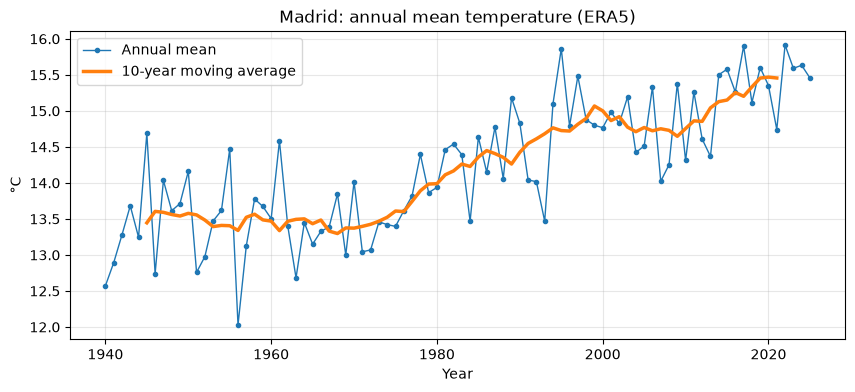

Mean 1940–1969: 13.43 °C
Mean 1996–2025: 15.06 °C
Difference: +1.63 °C


In [8]:
annual = daily.groupby(daily["date"].dt.year)["t_mean"].mean()
moving_10 = annual.rolling(10, center=True).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    annual.index,
    annual.values,
    marker="o",
    markersize=3,
    linewidth=1,
    label="Annual mean",
)
ax.plot(
    moving_10.index, moving_10.values, linewidth=2.5, label="10-year moving average"
)
ax.set_title(f"{CITY}: annual mean temperature (ERA5)")
ax.set_xlabel("Year")
ax.set_ylabel("°C")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

first = annual.loc[FIRST_YEAR : FIRST_YEAR + 29].mean()
last = annual.loc[LAST_YEAR - 29 : LAST_YEAR].mean()
print(f"Mean {FIRST_YEAR}–{FIRST_YEAR + 29}: {first:.2f} °C")
print(f"Mean {LAST_YEAR - 29}–{LAST_YEAR}: {last:.2f} °C")
print(f"Difference: {last - first:+.2f} °C")

## 6. How many "calls" does a city cost?

The response does not say how many calls were used. The rule published at
[open-meteo.com/en/pricing](https://open-meteo.com/en/pricing) says that a request with **more
than 10 variables** or **more than 2 weeks of data** counts as several calls, but not what
happens with **fewer** than 10 variables.

The exact answer is in the Open-Meteo source code, which is open: the function
[`calculateQueryWeight`](https://github.com/open-meteo/open-meteo/blob/main/Sources/App/Helper/Writer/ForecastApiResult.swift)
computes, for each location:

```
variables_fraction = (variables × models) / 10
days_fraction      = days / 14
calls              = max(1, variables_fraction, variables_fraction × days_fraction)
```

So **3 variables count as 0.3** (not as 1) and the cost grows linearly with the days.
`request_cost` implements that formula.

In [9]:
n_days = len(daily)
city_cost = request_cost(n_days)

print(
    f"One full city ({n_days:,} days, {len(DAILY_VARIABLES)} variables): {city_cost:.1f} calls"
)
print(
    f"With a single variable:                    {request_cost(n_days, n_variables=1):.1f} calls"
)
print(f"Adding one new year (365 days):            {request_cost(365):.1f} calls")

pd.DataFrame(
    {
        "limit (calls)": RATE_LIMITS,
        "cities that fit": {
            period: limit / city_cost for period, limit in RATE_LIMITS.items()
        },
    }
).round(1)

One full city (31,412 days, 3 variables): 673.1 calls
With a single variable:                    224.4 calls
Adding one new year (365 days):            7.8 calls


,limit (calls),cities that fit
minute,600,0.9
hour,5000,7.4
day,10000,14.9
month,300000,445.7


## Conclusions

1. **Format:** `daily` has one list per variable aligned with `time`, so it goes straight into a
   DataFrame (`to_dataframe`).
2. **Coverage:** ERA5 has data from **1940-01-01**, with no gaps and no empty values for Madrid
   (31,412 days), and always `t_min ≤ t_mean ≤ t_max`.
3. **Grid:** the API returns the nearest ERA5 cell (0.25°). The download must store the
   **returned** latitude/longitude/elevation (`grid_cell`), not only the requested ones.
4. **Model:** the default model uses another cell and gives +0.17 °C on average in 2024 (up to
   2.7 °C on one day). We always ask for `models=era5`, so the whole series comes from one source.
5. **First result:** in Madrid, 1996–2025 is **+1.6 °C** warmer than 1940–1969.
6. **Cost:** a full city costs **~673 calls** (`request_cost`, same formula as the Open-Meteo
   source code):
   - a single request is above the per-minute limit, so the download has to **wait more than
     one minute between cities** and retry on `429`;
   - the daily limit is the one that matters: **about 14 cities a day**;
   - splitting a request saves nothing, because the cost is linear in days;
   - adding a new year costs only ~8 calls per city.

   That is why the download of step 3 has to be **resumable**: 140 cities take about 10 days.